In [2]:
# This model is adapted from code generated by Claude (Anthropic, 2026), modified by the author.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, recall_score, f1_score
import matplotlib.pyplot as plt


(4012, 561) (1593, 561)
              precision    recall  f1-score   support

     sitting       0.96      0.89      0.93       508
   stand-sit       0.86      0.91      0.88        33
    standing       0.91      0.97      0.94       556
     walking       1.00      1.00      1.00       496

    accuracy                           0.95      1593
   macro avg       0.93      0.94      0.94      1593
weighted avg       0.95      0.95      0.95      1593



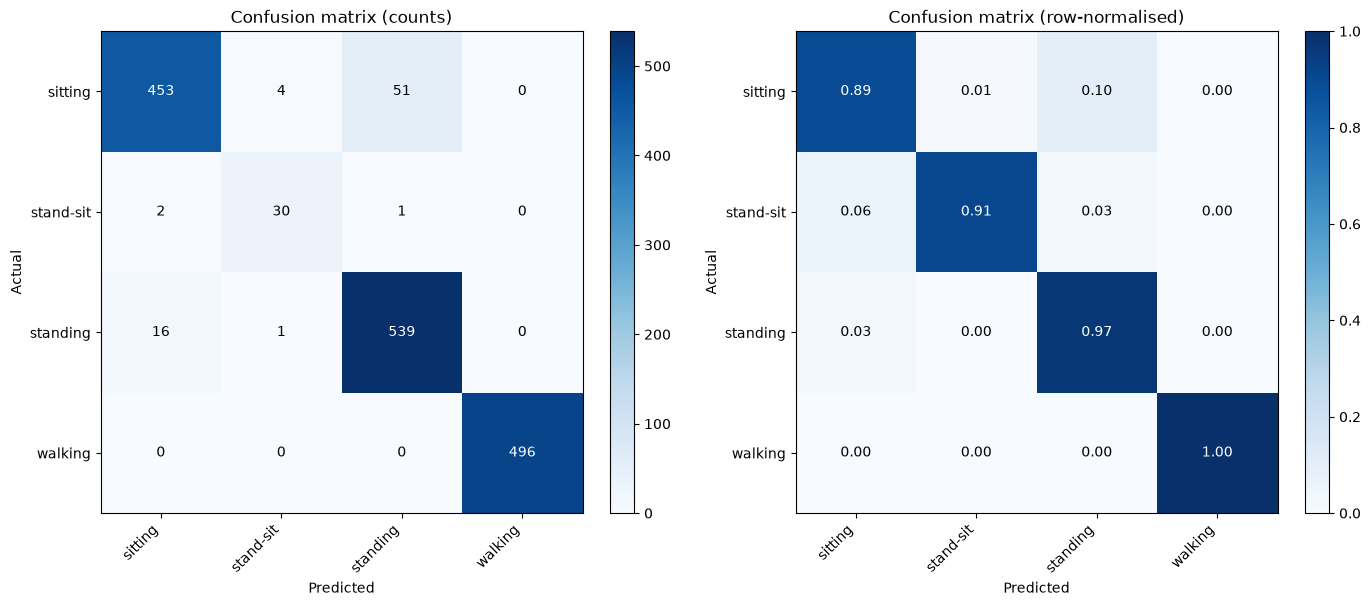

In [ ]:

#LOAD NAMES AND LABELS
BASE = Path(r"C:\Users\Sam\Downloads\archive")
feat_names = pd.read_csv(BASE / "features.txt", sep=r"\s+", header=None)[0].tolist()
act = pd.read_csv(BASE / "activity_labels.txt", sep=r"\s+", header=None, index_col=0)[1].to_dict()

#LOAD DATA
def load(split):
    X = pd.read_csv(BASE / split / f"X_{split.lower()}.txt", sep=r"\s+", header=None)
    y = pd.read_csv(BASE / split / f"y_{split.lower()}.txt", header=None)[0].map(act)
    s = pd.read_csv(BASE / split / f"subject_id_{split.lower()}.txt", header=None)[0]
    return X, y.to_numpy(), s.to_numpy()

X_train, y_train, s_train = load("Train")
X_test,  y_test,  s_test  = load("Test")


#Keep dictionary
keep = {"WALKING": "walking", "SITTING": "sitting", "STANDING": "standing",
        "STAND_TO_SIT": "stand-sit", "SIT_TO_STAND": "stand-sit"}

#FILTER CLASSES
def filter_classes(X, y):
    mask = pd.Series(y).isin(keep).to_numpy()
    return X[mask], pd.Series(y[mask]).map(keep).to_numpy()


X_train, y_train = filter_classes(X_train, y_train)
X_test,  y_test  = filter_classes(X_test,  y_test)
print(X_train.shape, X_test.shape)   # should be thousands of rows, not 0

#CREATE MODEL
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, class_weight="balanced", random_state=42),
)
model.fit(X_train, y_train)
preds = model.predict(X_test)

#OUTPUT METRICS
print(classification_report(y_test, preds, zero_division=0))






